Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-klass-rnn-rekurrentnogo-sloya

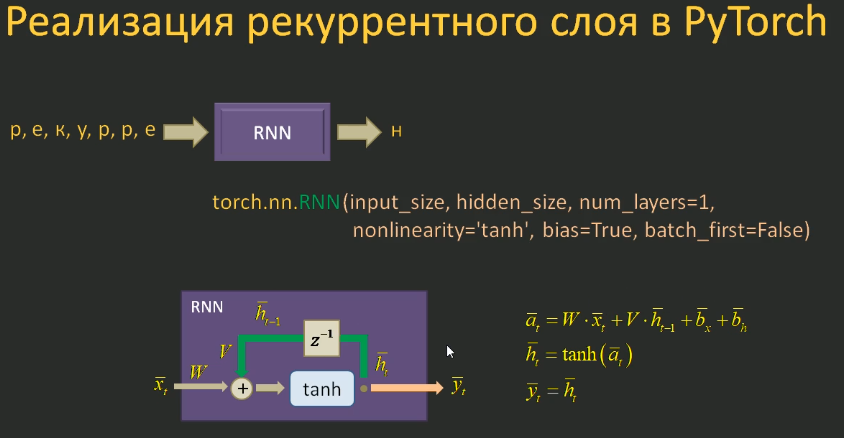

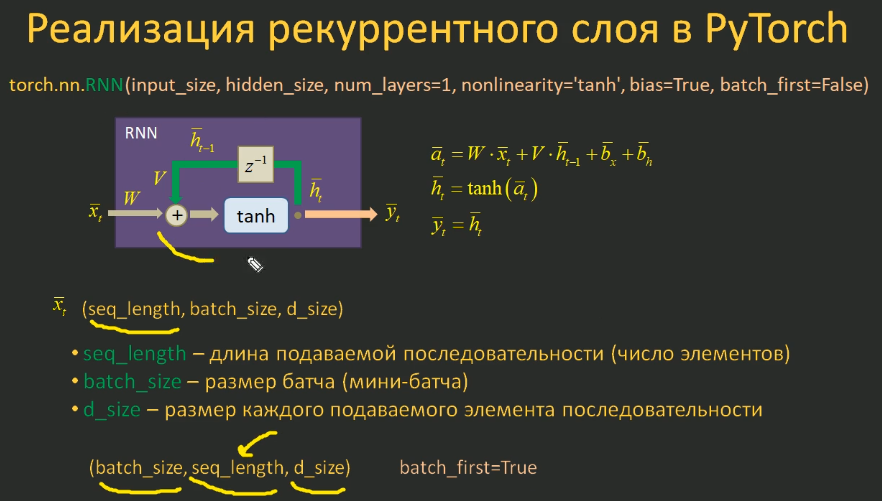

В простых рекуррентных блоках велик риск затухания градиента, особенно когда длина последовательности большая. С этим справляются в сетях LSTM и GRU  
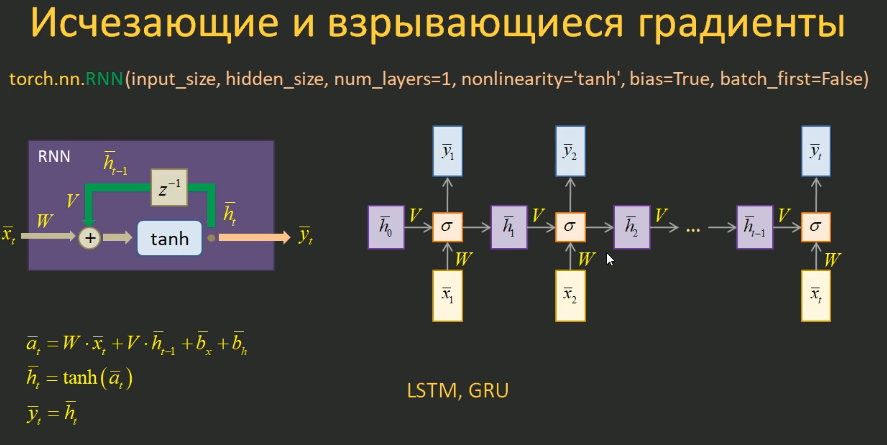  
Также может случиться проблема взрывающихся градиентов, но это решается обрезкой значений по некому пороговому значению

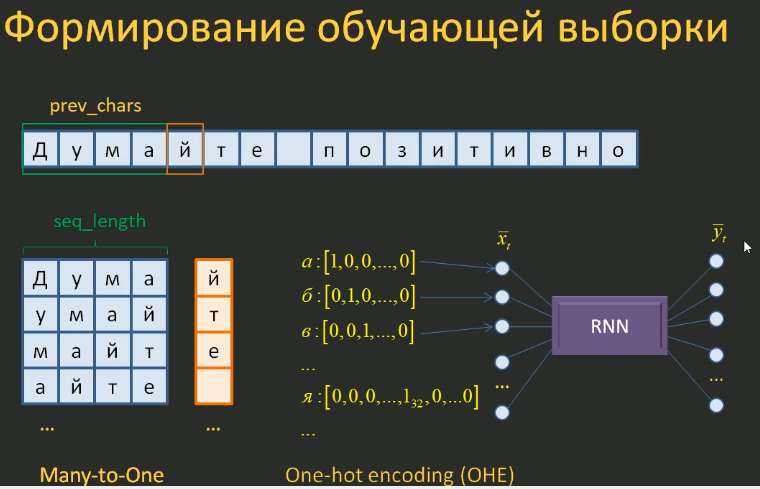

У нас есть последовательность букв, по которой мы угадываем следующую букву. то есть seq_length=4. Каждую букву мы шифруем через вектор, у которого единичка находится на позиции порядкового номера по алфавиту. то есть каждая буква это вектор длиной d_size=33

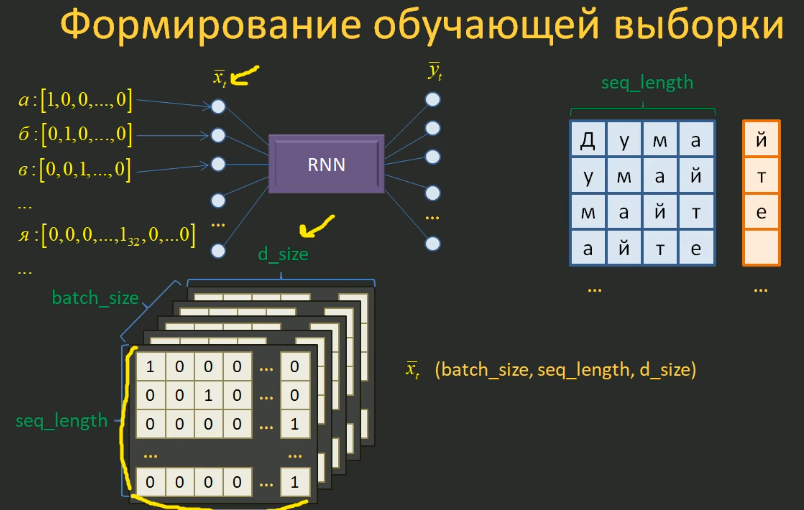

In [10]:
import torch
import torch.nn as nn
 
rnn = nn.RNN(input_size=33, hidden_size=64, batch_first=True)
 
x = torch.randn(8, 3, 33)
h0 = torch.randn(1, 8, 64)
y, h = rnn(x, h0)
 
print('y:', y.shape)
print('h:', h.shape)

y: torch.Size([8, 3, 64])
h: torch.Size([1, 8, 64])


Y содержит выходы с каждой ячейки, а h только с последней

***В общем важно запомнить***  
Для инициализации слоя RNN нужно знать только сколько нейронов к нему придет (input_size) и какое скрытое пространство по этому входу надо сформировать (hidden_size). И еще num_layers (это сколько подряд ячеек поставить)  

На вход в модель нужно подавать данные в формате (batch_size, seq_length, d_size==input_size)  

на выходе модель возвращает:  
y (batch_size, seq_length, hidden_size)  
h (num_layers, batch_size, hidden_size)  
